In [117]:
import numpy as np
import pandas as pd

from mlxtend.plotting import plot_decision_regions
from sklearn.tree import DecisionTreeClassifier, plot_tree

import warnings
warnings.filterwarnings('ignore')

In [118]:
df = pd.DataFrame()

In [119]:
df['X1'] = [1,2,3,4,5,6,6,7,9,9]
df['X2'] = [5,3,6,8,1,9,5,8,9,2]
df['label'] = [1,1,0,1,0,1,0,1,0,0]

In [120]:
df

,X1,X2,label
0,1,5,1
1,2,3,1
2,3,6,0
3,4,8,1
4,5,1,0
5,6,9,1
6,6,5,0
7,7,8,1
8,9,9,0
9,9,2,0


<Axes: xlabel='X1', ylabel='X2'>

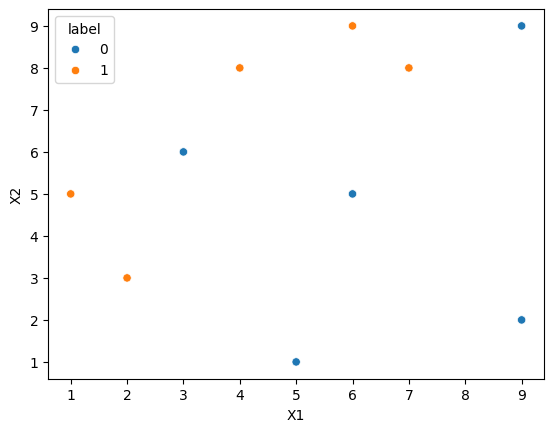

In [121]:
import seaborn as sns
sns.scatterplot(x = df['X1'], y = df['X2'], hue = df['label'])

In [122]:
df['weights'] = 1/df.shape[0]
df

,X1,X2,label,weights
0,1,5,1,0.1
1,2,3,1,0.1
2,3,6,0,0.1
3,4,8,1,0.1
4,5,1,0,0.1
5,6,9,1,0.1
6,6,5,0,0.1
7,7,8,1,0.1
8,9,9,0,0.1
9,9,2,0,0.1


In [123]:
# Decision Stumps
dt1 = DecisionTreeClassifier(max_depth = 1)

In [124]:
X=df.iloc[:, 0:2].values
y=df.iloc[:,2].values

In [125]:
dt1.fit(X,y)

DecisionTreeClassifier(max_depth=1)

[Text(0.5, 0.75, 'x[1] <= 2.5\ngini = 0.5\nsamples = 10\nvalue = [5, 5]'),
 Text(0.25, 0.25, 'gini = 0.0\nsamples = 2\nvalue = [2, 0]'),
 Text(0.375, 0.5, 'True  '),
 Text(0.75, 0.25, 'gini = 0.469\nsamples = 8\nvalue = [3, 5]'),
 Text(0.625, 0.5, '  False')]

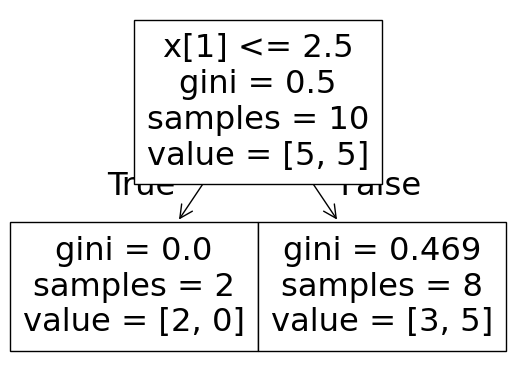

In [126]:
plot_tree(dt1)

<Axes: >

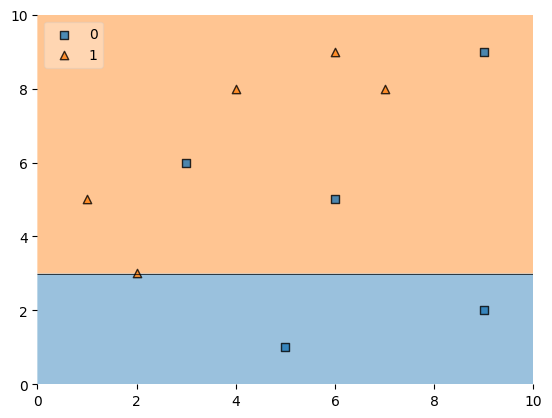

In [127]:
plot_decision_regions(X, y, dt1, legend=2)

In [128]:
df['predicted'] = dt1.predict(X)
df

,X1,X2,label,weights,predicted
0,1,5,1,0.1,1
1,2,3,1,0.1,1
2,3,6,0,0.1,1
3,4,8,1,0.1,1
4,5,1,0,0.1,0
5,6,9,1,0.1,1
6,6,5,0,0.1,1
7,7,8,1,0.1,1
8,9,9,0,0.1,1
9,9,2,0,0.1,0


In [129]:
# Function to calculate error
def error(df):
  return (df[df['predicted']!=df['label']]['weights'].sum())

In [130]:
# Function to calculate alpha
def alpha(df):
  err_val = error(df)
  return 0.5*np.log((1-err_val)/(err_val + 0.00000001))

In [131]:
err_value = error(df)
err_value

np.float64(0.30000000000000004)

In [132]:
alpha_value1 = alpha(df)
alpha_value1

np.float64(0.42364891352693534)

In [133]:
df['updated_weights'] = np.where(
    df['predicted'] == df['label'],
    df['weights']*np.exp(-alpha_value1),
    df['weights']*np.exp(alpha_value1)
)
df

,X1,X2,label,weights,predicted,updated_weights
0,1,5,1,0.1,1,0.065465
1,2,3,1,0.1,1,0.065465
2,3,6,0,0.1,1,0.152753
3,4,8,1,0.1,1,0.065465
4,5,1,0,0.1,0,0.065465
5,6,9,1,0.1,1,0.065465
6,6,5,0,0.1,1,0.152753
7,7,8,1,0.1,1,0.065465
8,9,9,0,0.1,1,0.152753
9,9,2,0,0.1,0,0.065465


In [134]:
# Normalized Weights
df['normalized_weights'] = df['updated_weights']/df['updated_weights'].sum()
df

,X1,X2,label,weights,predicted,updated_weights,normalized_weights
0,1,5,1,0.1,1,0.065465,0.071429
1,2,3,1,0.1,1,0.065465,0.071429
2,3,6,0,0.1,1,0.152753,0.166667
3,4,8,1,0.1,1,0.065465,0.071429
4,5,1,0,0.1,0,0.065465,0.071429
5,6,9,1,0.1,1,0.065465,0.071429
6,6,5,0,0.1,1,0.152753,0.166667
7,7,8,1,0.1,1,0.065465,0.071429
8,9,9,0,0.1,1,0.152753,0.166667
9,9,2,0,0.1,0,0.065465,0.071429


In [135]:
# Calculate lower and upper boundaries
df['upper_range'] = df['normalized_weights'].cumsum()
df['lower_range'] = df['upper_range'] - df['normalized_weights']
df

,X1,X2,label,weights,predicted,updated_weights,normalized_weights,upper_range,lower_range
0,1,5,1,0.1,1,0.065465,0.071429,0.071429,0.000000
1,2,3,1,0.1,1,0.065465,0.071429,0.142857,0.071429
2,3,6,0,0.1,1,0.152753,0.166667,0.309524,0.142857
3,4,8,1,0.1,1,0.065465,0.071429,0.380952,0.309524
4,5,1,0,0.1,0,0.065465,0.071429,0.452381,0.380952
5,6,9,1,0.1,1,0.065465,0.071429,0.523810,0.452381
6,6,5,0,0.1,1,0.152753,0.166667,0.690476,0.523810
7,7,8,1,0.1,1,0.065465,0.071429,0.761905,0.690476
8,9,9,0,0.1,1,0.152753,0.166667,0.928571,0.761905
9,9,2,0,0.1,0,0.065465,0.071429,1.000000,0.928571


In [136]:
def create_new_dataset(df):

  indices = []

  for i in range(df.shape[0]):
    a = np.random.random()
    for index,row in df.iterrows():
      if row['upper_range'] > a and a > row['lower_range']:
        indices.append(index)
  return indices


In [137]:
index_values = create_new_dataset(df)
index_values

[9, 2, 2, 1, 8, 4, 2, 6, 6, 5]

In [138]:
new_df = df.iloc[index_values, [0,1,2,3]]
new_df

,X1,X2,label,weights
9,9,2,0,0.1
2,3,6,0,0.1
2,3,6,0,0.1
1,2,3,1,0.1
8,9,9,0,0.1
4,5,1,0,0.1
2,3,6,0,0.1
6,6,5,0,0.1
6,6,5,0,0.1
5,6,9,1,0.1


In [139]:
dt2 = DecisionTreeClassifier(max_depth = 1)

In [140]:
X=new_df.iloc[:, 0:2].values
y=new_df.iloc[:,2].values

In [141]:
dt2.fit(X,y)

DecisionTreeClassifier(max_depth=1)

[Text(0.5, 0.75, 'x[0] <= 2.5\ngini = 0.32\nsamples = 10\nvalue = [8, 2]'),
 Text(0.25, 0.25, 'gini = 0.0\nsamples = 1\nvalue = [0, 1]'),
 Text(0.375, 0.5, 'True  '),
 Text(0.75, 0.25, 'gini = 0.198\nsamples = 9\nvalue = [8, 1]'),
 Text(0.625, 0.5, '  False')]

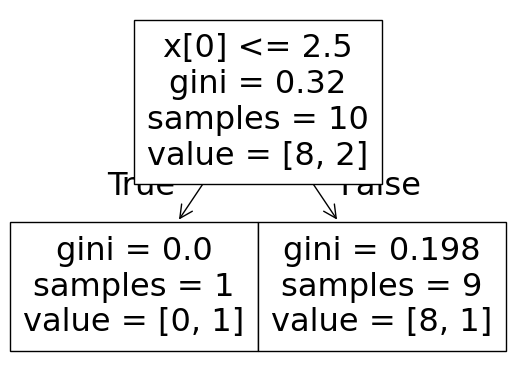

In [142]:
plot_tree(dt2)

<Axes: >

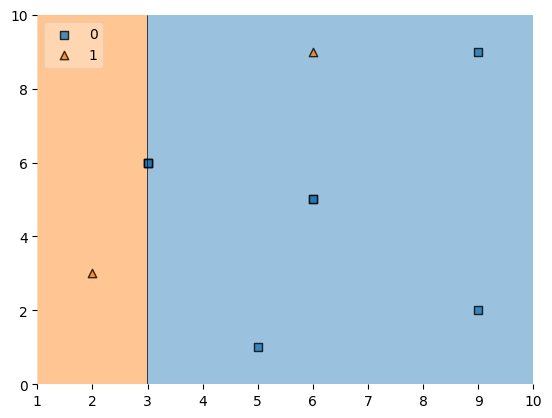

In [143]:
plot_decision_regions(X, y, dt2, legend=2)

In [144]:
new_df['predicted'] = dt2.predict(X)
new_df

,X1,X2,label,weights,predicted
9,9,2,0,0.1,0
2,3,6,0,0.1,0
2,3,6,0,0.1,0
1,2,3,1,0.1,1
8,9,9,0,0.1,0
4,5,1,0,0.1,0
2,3,6,0,0.1,0
6,6,5,0,0.1,0
6,6,5,0,0.1,0
5,6,9,1,0.1,0


In [145]:
err_value = error(new_df)
err_value

np.float64(0.1)

In [146]:
alpha_value2 = alpha(new_df)
alpha_value2

np.float64(1.0986122386681123)

In [147]:
new_df['updated_weights'] = np.where(
    new_df['predicted'] == new_df['label'],
    new_df['weights']*np.exp(-alpha_value2),
    new_df['weights']*np.exp(alpha_value2)
)
new_df

,X1,X2,label,weights,predicted,updated_weights
9,9,2,0,0.1,0,0.033333
2,3,6,0,0.1,0,0.033333
2,3,6,0,0.1,0,0.033333
1,2,3,1,0.1,1,0.033333
8,9,9,0,0.1,0,0.033333
4,5,1,0,0.1,0,0.033333
2,3,6,0,0.1,0,0.033333
6,6,5,0,0.1,0,0.033333
6,6,5,0,0.1,0,0.033333
5,6,9,1,0.1,0,0.300000


In [148]:
new_df['normalized_weights'] = new_df['updated_weights']/new_df['updated_weights'].sum()
new_df

,X1,X2,label,weights,predicted,updated_weights,normalized_weights
9,9,2,0,0.1,0,0.033333,0.055556
2,3,6,0,0.1,0,0.033333,0.055556
2,3,6,0,0.1,0,0.033333,0.055556
1,2,3,1,0.1,1,0.033333,0.055556
8,9,9,0,0.1,0,0.033333,0.055556
4,5,1,0,0.1,0,0.033333,0.055556
2,3,6,0,0.1,0,0.033333,0.055556
6,6,5,0,0.1,0,0.033333,0.055556
6,6,5,0,0.1,0,0.033333,0.055556
5,6,9,1,0.1,0,0.300000,0.500000


In [149]:
new_df['upper_range'] = new_df['normalized_weights'].cumsum()
new_df['lower_range'] = new_df['upper_range'] - new_df['normalized_weights']
new_df

,X1,X2,label,weights,predicted,updated_weights,normalized_weights,upper_range,lower_range
9,9,2,0,0.1,0,0.033333,0.055556,0.055556,0.000000
2,3,6,0,0.1,0,0.033333,0.055556,0.111111,0.055556
2,3,6,0,0.1,0,0.033333,0.055556,0.166667,0.111111
1,2,3,1,0.1,1,0.033333,0.055556,0.222222,0.166667
8,9,9,0,0.1,0,0.033333,0.055556,0.277778,0.222222
4,5,1,0,0.1,0,0.033333,0.055556,0.333333,0.277778
2,3,6,0,0.1,0,0.033333,0.055556,0.388889,0.333333
6,6,5,0,0.1,0,0.033333,0.055556,0.444444,0.388889
6,6,5,0,0.1,0,0.033333,0.055556,0.500000,0.444444
5,6,9,1,0.1,0,0.300000,0.500000,1.000000,0.500000


In [150]:
index_vlaues = create_new_dataset(new_df)
index_values

[9, 2, 2, 1, 8, 4, 2, 6, 6, 5]

In [151]:
new_df2 = new_df.iloc[index_values, [0,1,2,3]]
new_df2

,X1,X2,label,weights
5,6,9,1,0.1
2,3,6,0,0.1
2,3,6,0,0.1
2,3,6,0,0.1
6,6,5,0,0.1
8,9,9,0,0.1
2,3,6,0,0.1
2,3,6,0,0.1
2,3,6,0,0.1
4,5,1,0,0.1


In [152]:
dt3 = DecisionTreeClassifier(max_depth = 1)
X = new_df2.iloc[:, 0:2].values
y = new_df2.iloc[:,2].values

dt3.fit(X,y)

DecisionTreeClassifier(max_depth=1)

[Text(0.5, 0.75, 'x[1] <= 7.5\ngini = 0.18\nsamples = 10\nvalue = [9, 1]'),
 Text(0.25, 0.25, 'gini = 0.0\nsamples = 8\nvalue = [8, 0]'),
 Text(0.375, 0.5, 'True  '),
 Text(0.75, 0.25, 'gini = 0.5\nsamples = 2\nvalue = [1, 1]'),
 Text(0.625, 0.5, '  False')]

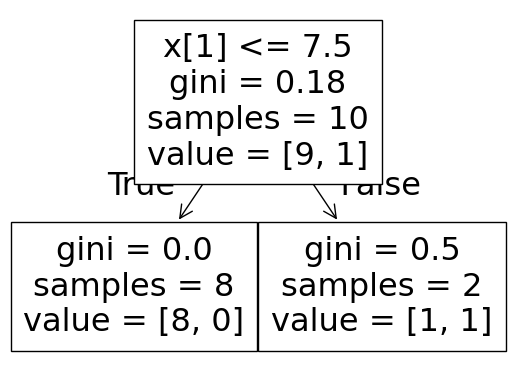

In [153]:
plot_tree(dt3)

<Axes: >

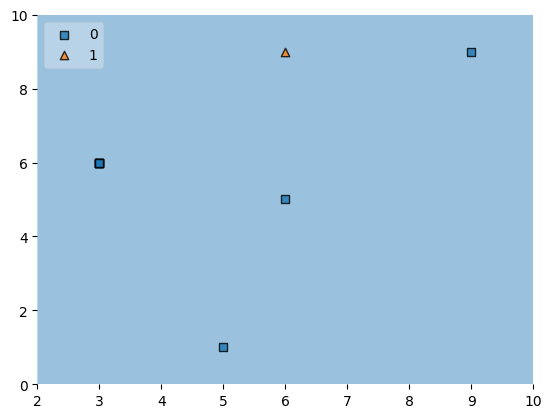

In [154]:
plot_decision_regions(X, y, dt3, legend=2)

In [155]:
new_df2['predicted'] = dt3.predict(X)
new_df2

,X1,X2,label,weights,predicted
5,6,9,1,0.1,0
2,3,6,0,0.1,0
2,3,6,0,0.1,0
2,3,6,0,0.1,0
6,6,5,0,0.1,0
8,9,9,0,0.1,0
2,3,6,0,0.1,0
2,3,6,0,0.1,0
2,3,6,0,0.1,0
4,5,1,0,0.1,0


In [156]:
err_value = error(new_df2)
err_value

np.float64(0.1)

In [157]:
alpha_value3 = alpha(new_df2)
alpha_value3

np.float64(1.0986122386681123)

# Prediction

In [158]:
new_data = np.array([9,	9]).reshape(1,-1)

In [159]:
dt1.predict(new_data)

array([1])

In [160]:
dt2.predict(new_data)

array([0])

In [161]:
dt3.predict(new_data)

array([0])

In [163]:
np.sign(alpha_value1*(1) + alpha_value2*(-1) + alpha_value3*(-1))

np.float64(-1.0)